In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Load dataset
df = pd.read_csv('website_wata.csv')

# Quick sanity check on shape, nulls, and duplicates
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print("\nMissing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

df.head()

Rows: 2000, Columns: 7

Missing values:
 Page Views          0
Session Duration    0
Bounce Rate         0
Traffic Source      0
Time on Page        0
Previous Visits     0
Conversion Rate     0
dtype: int64
Duplicate rows: 0


,Page Views,Session Duration,Bounce Rate,Traffic Source,Time on Page,Previous Visits,Conversion Rate
0,5,11.051381,0.230652,Organic,3.890460,3,1.0
1,4,3.429316,0.391001,Social,8.478174,0,1.0
2,4,1.621052,0.397986,Organic,9.636170,2,1.0
3,5,3.629279,0.180458,Organic,2.071925,3,1.0
4,5,4.235843,0.291541,Paid,1.960654,5,1.0


In [2]:
# Summary stats for core engagement metrics
summary = df[['Page Views', 'Session Duration', 'Bounce Rate', 'Time on Page', 'Previous Visits', 'Conversion Rate']].describe().round(2)
print(summary)

# Check anomalies: 14 rows have 0 page views despite active session duration
zero_pv = df[df['Page Views'] == 0]
print(f"\nSessions recorded with 0 Page Views: {len(zero_pv)}")

       Page Views  Session Duration  Bounce Rate  Time on Page  \
count     2000.00           2000.00      2000.00       2000.00   
mean         4.95              3.02         0.28          4.03   
std          2.18              3.10         0.16          2.89   
min          0.00              0.00         0.01          0.07   
25%          3.00              0.82         0.16          1.94   
50%          5.00              1.99         0.27          3.32   
75%          6.00              4.20         0.39          5.41   
max         14.00             20.29         0.84         24.80   

       Previous Visits  Conversion Rate  
count          2000.00          2000.00  
mean              1.98             0.98  
std               1.43             0.07  
min               0.00             0.34  
25%               1.00             1.00  
50%               2.00             1.00  
75%               3.00             1.00  
max               9.00             1.00  

Sessions recorded with 0 P

In [3]:
# Breakdown by Traffic Source
channel_perf = df.groupby('Traffic Source').agg(
    Sessions=('Page Views', 'count'),
    Avg_Page_Views=('Page Views', 'mean'),
    Avg_Session_Min=('Session Duration', 'mean'),
    Avg_Bounce_Rate=('Bounce Rate', 'mean'),
    Avg_Time_On_Page=('Time on Page', 'mean'),
    Avg_Conversion=('Conversion Rate', 'mean')
).round(3).sort_values(by='Sessions', ascending=False)

print(channel_perf)

                Sessions  Avg_Page_Views  Avg_Session_Min  Avg_Bounce_Rate  \
Traffic Source                                                               
Organic              786           5.025            3.104            0.282   
Paid                 428           4.944            2.943            0.296   
Referral             301           4.983            3.125            0.266   
Social               269           4.695            3.057            0.296   
Direct               216           4.963            2.692            0.285   

                Avg_Time_On_Page  Avg_Conversion  
Traffic Source                                    
Organic                    3.978           0.982  
Paid                       4.087           0.979  
Referral                   3.985           0.988  
Social                     4.188           0.983  
Direct                     3.949           0.979  


In [4]:
# New vs Returning Visitor segmentation
df['Visitor_Segment'] = np.where(df['Previous Visits'] == 0, 'New Visitor', 'Returning Visitor')

visitor_comp = df.groupby('Visitor_Segment').agg(
    Count=('Page Views', 'count'),
    Avg_Page_Views=('Page Views', 'mean'),
    Avg_Duration_Min=('Session Duration', 'mean'),
    Avg_Bounce_Rate=('Bounce Rate', 'mean'),
    Avg_Conversion=('Conversion Rate', 'mean')
).round(3)

print(visitor_comp)

                   Count  Avg_Page_Views  Avg_Duration_Min  Avg_Bounce_Rate  \
Visitor_Segment                                                               
New Visitor          282           4.979             3.154            0.284   
Returning Visitor   1718           4.946             3.000            0.285   

                   Avg_Conversion  
Visitor_Segment                    
New Visitor                 0.968  
Returning Visitor           0.984  


In [7]:
# User Journey & Engagement Drop-Off Mapping
stage_1 = len(df)
stage_2 = len(df[df['Page Views'] >= 2])
stage_3 = len(df[(df['Page Views'] >= 2) & (df['Session Duration'] >= 1.5)])
stage_4 = len(df[(df['Page Views'] >= 2) & (df['Session Duration'] >= 1.5) & (df['Bounce Rate'] < 0.35)])
stage_5 = len(df[(df['Page Views'] >= 2) & (df['Session Duration'] >= 1.5) & (df['Bounce Rate'] < 0.35) & (df['Conversion Rate'] >= 0.95)])

funnel_df = pd.DataFrame({
    'Stage': [
        '1. All Sessions',
        '2. Multi-Page Viewers (2+ Pages)',
        '3. Engaged Sessions (>= 1.5 Mins)',
        '4. Low-Bounce Intent (< 35% Bounce)',
        '5. High Conversion (>= 95% Rate)'
    ],
    'Users': [stage_1, stage_2, stage_3, stage_4, stage_5]
})

funnel_df['Retention_%'] = (funnel_df['Users'] / stage_1 * 100).round(1)
funnel_df['Step_Dropoff_%'] = (funnel_df['Users'].pct_change().fillna(0) * -100).round(1)
print(funnel_df)

                                 Stage  Users  Retention_%  Step_Dropoff_%
0                      1. All Sessions   2000        100.0            -0.0
1     2. Multi-Page Viewers (2+ Pages)   1917         95.9             4.1
2    3. Engaged Sessions (>= 1.5 Mins)   1144         57.2            40.3
3  4. Low-Bounce Intent (< 35% Bounce)    803         40.2            29.8
4     5. High Conversion (>= 95% Rate)    778         38.9             3.1


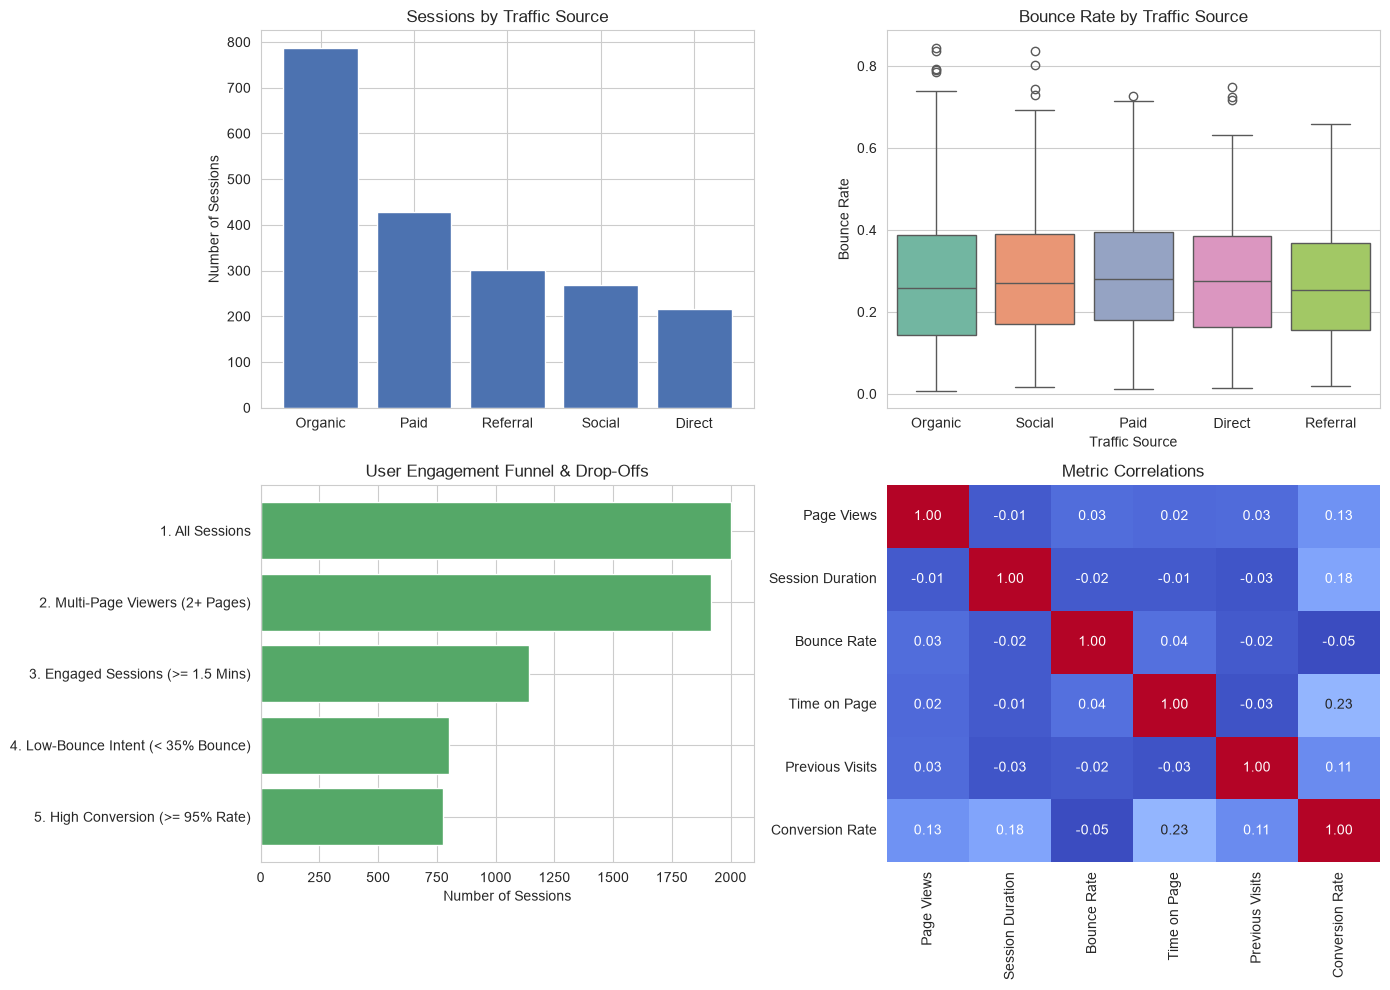

In [6]:
# Visualizations
sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Traffic Share by Source
source_counts = df['Traffic Source'].value_counts()
axes[0, 0].bar(source_counts.index, source_counts.values, color='#4C72B0')
axes[0, 0].set_title('Sessions by Traffic Source')
axes[0, 0].set_ylabel('Number of Sessions')

# 2. Bounce Rate Distribution across Channels
sns.boxplot(data=df, x='Traffic Source', y='Bounce Rate', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Bounce Rate by Traffic Source')

# 3. User Journey / Engagement Funnel
axes[1, 0].barh(funnel_df['Stage'][::-1], funnel_df['Users'][::-1], color='#55A868')
axes[1, 0].set_title('User Engagement Funnel & Drop-Offs')
axes[1, 0].set_xlabel('Number of Sessions')

# 4. Feature Correlation Heatmap
corr = df[['Page Views', 'Session Duration', 'Bounce Rate', 'Time on Page', 'Previous Visits', 'Conversion Rate']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1, 1], cbar=False)
axes[1, 1].set_title('Metric Correlations')

plt.tight_layout()
plt.savefig('traffic_analysis_charts.png', dpi=150)
plt.show()

# Web Traffic Analytics

## Overview
This project analyzes 2,000 website sessions (`website_wata.csv`) to evaluate user engagement, traffic channel performance, and drop-off behavior across the visitor journey.

## Key Metrics Summary
- **Total Sessions:** 2,000 (no missing values or duplicate records; 14 sessions logged `0` page views, pointing to minor tracking misfires).
- **Average Page Views:** 4.95 pages per session (median: 5.0).
- **Average Session Duration:** 3.02 minutes (median: 1.99 minutes, skewed by long-tail sessions up to 20.3 minutes; 593 sessions lasted under 1 minute).
- **Average Bounce Rate:** 28.5% (215 sessions had bounce rates above 50%).
- **Average Time on Page:** 4.03 minutes.

## Channel & Visitor Insights
- **Traffic Volume:** Organic search brings the largest share of traffic (786 sessions, 39.3%), followed by Paid (428), Referral (301), Social (269), and Direct (216).
- **Channel Quality:** Referral traffic has the lowest average bounce rate (26.6%) and longest session duration (3.13 mins). Social traffic records the lowest page views per session (4.70) and highest bounce rate (29.6%), meaning social visitors land on a page and exit faster than search or referral users.
- **New vs. Returning Visitors:** Returning visitors make up 85.9% of sessions (1,718 vs. 282 new visitors) and show slightly higher conversion rates (98.4% vs. 96.8%).
- **Conversion Drivers:** `Time on Page` (r = 0.23) and `Session Duration` (r = 0.18) show the strongest positive correlation with conversion rate.

## User Journey & Drop-Off Points
Mapping sessions across engagement depth highlights where users disengage:
1. **All Sessions:** 2,000 (100%)
2. **Multi-Page Viewers (2+ pages):** 1,917 (4.2% immediate single-page drop-off)
3. **Engaged Sessions (1.5+ mins):** 1,144 (**40.3% drop-off** — the steepest friction point, where users browse multiple pages briefly but leave within 90 seconds)
4. **Low-Bounce High-Intent (<35% bounce):** 803 (29.8% drop-off)
5. **High-Conversion Sessions:** 778 (3.1% drop-off once intent is established)

## Recommendations to Improve Engagement
1. **Fix the 90-second drop-off gap:** Nearly 30% of all sessions end in under 1 minute. Improving above-the-fold clarity and internal linking on top landing pages should help convert quick browsers into engaged readers.
2. **Audit Social landing pages:** Because Social traffic has the highest bounce rate (29.6%) and lowest page depth (4.70), align social ad/post copy more closely with landing page content.
3. **Investigate 0-page-view sessions:** 14 sessions logged duration without recording a page view, which usually indicates a firing delay in analytics tracking tags.